# Lab 01 – Sentiment Analysis Using Traditional Machine Learning
PUSL 3205 – Large Language Models and Generative AI

Objective: practice basic NLP tasks and evaluate a sentiment classifier.

## 1. Download and load the dataset

In [2]:

import io
import zipfile
import urllib.request
import re
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import (
    CountVectorizer,
    TfidfVectorizer,
    ENGLISH_STOP_WORDS
)
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay
)
from IPython.display import display

url = "https://archive.ics.uci.edu/static/public/331/sentiment+labelled+sentences.zip"

local = Path("sentiment.zip")
raw = local.read_bytes() if local.exists() else urllib.request.urlopen(url, timeout=60).read()

records = []

sources = {
    "amazon_cells_labelled.txt": "Amazon",
    "imdb_labelled.txt": "IMDb",
    "yelp_labelled.txt": "Yelp"
}

with zipfile.ZipFile(io.BytesIO(raw)) as z:
    for filename in z.namelist():
        basename = filename.split("/")[-1]

        if basename in sources and "__MACOSX" not in filename:
            content = z.read(filename).decode("utf-8", errors="replace")

            for line in content.splitlines():
                parts = line.rsplit("\t", 1)

                if len(parts) == 2:
                    text, label = parts

                    if label.strip() in ("0", "1") and text.strip():
                        records.append({
                            "text": text.strip(),
                            "label": int(label.strip()),
                            "source": sources[basename]
                        })

df = pd.DataFrame(records)

assert len(df) == 3000, f"Unexpected dataset size: {len(df)}"

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())
display(df.label.value_counts())


Dataset loaded successfully!
Dataset shape: (3000, 3)


,text,label,source
0,So there is no way for me to plug it in here i...,0,Amazon
1,"Good case, Excellent value.",1,Amazon
2,Great for the jawbone.,1,Amazon
3,Tied to charger for conversations lasting more...,0,Amazon
4,The mic is great.,1,Amazon


,count
label,
0,1500
1,1500


## 2. Text preprocessing

In [3]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()
df['clean_text'] = df['text'].apply(clean_text)
display(df[['text','clean_text']].head(10))

,text,clean_text
0,So there is no way for me to plug it in here i...,so there is no way for me to plug it in here i...
1,"Good case, Excellent value.",good case excellent value
2,Great for the jawbone.,great for the jawbone
3,Tied to charger for conversations lasting more...,tied to charger for conversations lasting more...
4,The mic is great.,the mic is great
5,I have to jiggle the plug to get it to line up...,i have to jiggle the plug to get it to line up...
6,If you have several dozen or several hundred c...,if you have several dozen or several hundred c...
7,If you are Razr owner...you must have this!,if you are razr owner you must have this
8,"Needless to say, I wasted my money.",needless to say i wasted my money
9,What a waste of money and time!.,what a waste of money and time


## 3. Explore the text data

Positive


,text
1,"Good case, Excellent value."
2,Great for the jawbone.
4,The mic is great.
7,If you are Razr owner...you must have this!
10,And the sound quality is great.


Negative


,text
0,So there is no way for me to plug it in here i...
3,Tied to charger for conversations lasting more...
5,I have to jiggle the plug to get it to line up...
6,If you have several dozen or several hundred c...
8,"Needless to say, I wasted my money."


,0
great,201
good,177
s,144
film,105
phone,88
movie,86
t,65
best,63
food,60
place,58


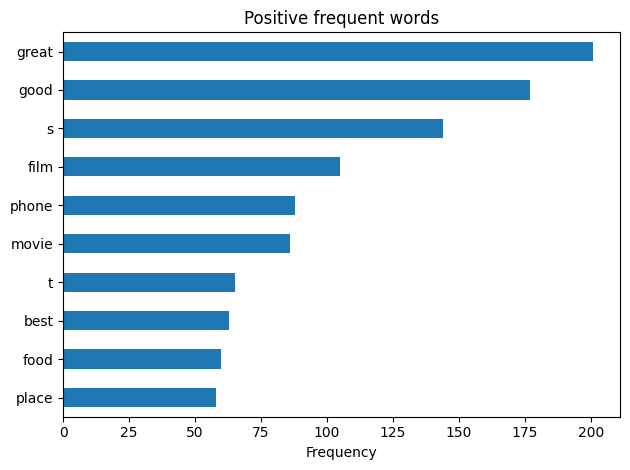

,0
t,216
s,109
bad,100
movie,96
phone,80
like,69
just,66
food,66
don,64
time,62


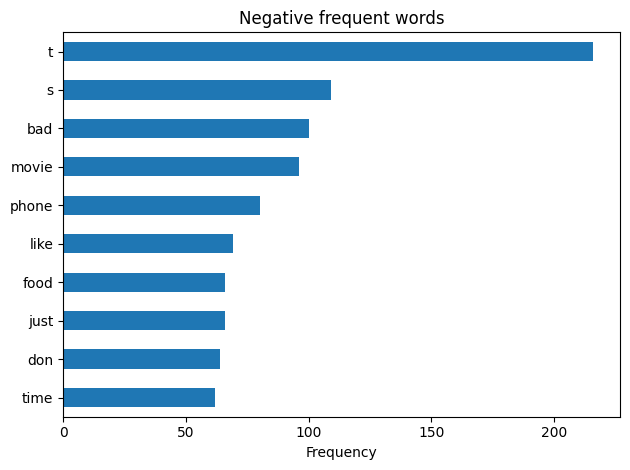

In [4]:
for label in [1, 0]:
    print('Positive' if label else 'Negative')
    display(df.loc[df.label == label, ['text']].head(5))
out = Path('../screenshots') if Path.cwd().name == 'notebooks' else Path('screenshots')
out.mkdir(exist_ok=True)
for label in [1, 0]:
    words = Counter(w for sentence in df.loc[df.label == label, 'clean_text'] for w in sentence.split() if w not in ENGLISH_STOP_WORDS)
    common = pd.Series(dict(words.most_common(10))).sort_values()
    display(common.sort_values(ascending=False))
    common.plot.barh(title=('Positive' if label else 'Negative') + ' frequent words')
    plt.xlabel('Frequency'); plt.tight_layout(); plt.savefig(out / f'words-{label}.png'); plt.show()


## 4. Split the dataset
Use a stratified 80/20 split. Fit vectorizers only on training data to avoid leakage.

In [5]:
data = df.drop_duplicates(subset=['clean_text']).copy()
X_train, X_test, y_train, y_test = train_test_split(data.clean_text, data.label, test_size=0.2, random_state=42, stratify=data.label)
print('Training:', len(X_train), 'Testing:', len(X_test))

Training: 2377 Testing: 595


## 5–6. Create BoW representation and train Logistic Regression
Compare with TF-IDF using the same split.

In [6]:
models = {'BoW': make_pipeline(CountVectorizer(), LogisticRegression(max_iter=1000)), 'TF-IDF': make_pipeline(TfidfVectorizer(), LogisticRegression(max_iter=1000))}
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, model[0].transform(X_train).shape)

BoW (2377, 4530)
TF-IDF (2377, 4530)


## 7. Evaluate performance
Precision, recall and F1 use the positive class (label 1).

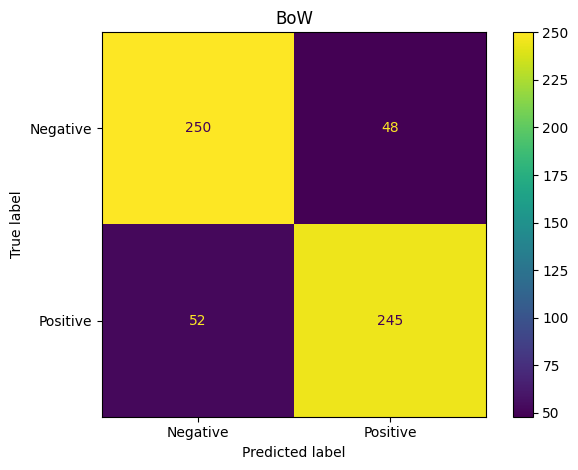

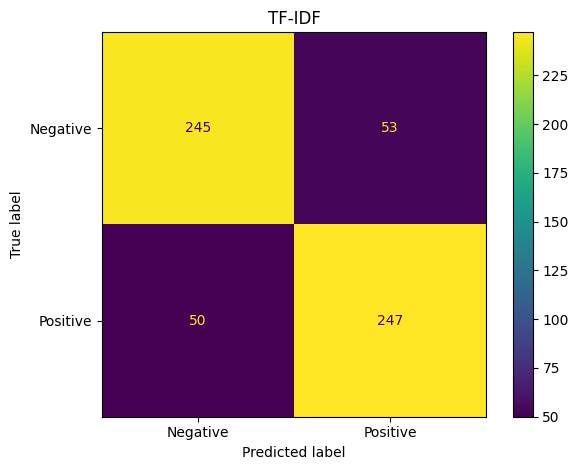

,Accuracy,Precision,Recall,F1
Model,,,,
BoW,0.8319,0.8362,0.8249,0.8305
TF-IDF,0.8269,0.8233,0.8316,0.8275


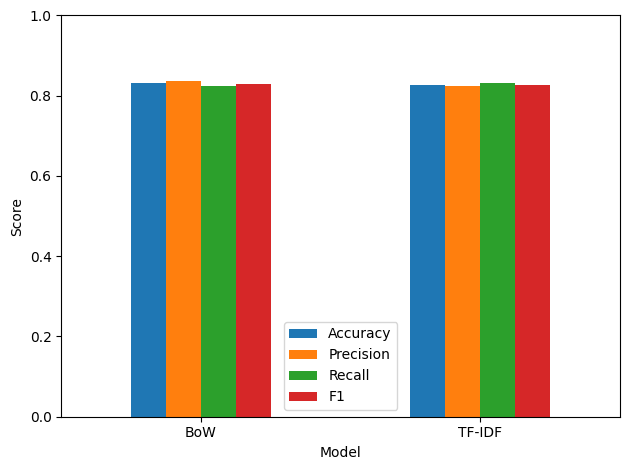

In [7]:
results = []
for name, model in models.items():
    pred = model.predict(X_test)
    results.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Precision':precision_score(y_test,pred,zero_division=0),'Recall':recall_score(y_test,pred,zero_division=0),'F1':f1_score(y_test,pred,zero_division=0)})
    ConfusionMatrixDisplay.from_predictions(y_test,pred,display_labels=['Negative','Positive'])
    plt.title(name); plt.tight_layout(); plt.savefig(out / f'{name}-confusion.png'); plt.show()
metrics = pd.DataFrame(results).set_index('Model')
display(metrics.round(4))
metrics.to_csv(out / 'metrics.csv')
metrics.plot.bar(ylim=(0,1), rot=0); plt.ylabel('Score'); plt.tight_layout(); plt.savefig(out / 'model-comparison.png'); plt.show()

## 8. Test new sentences

In [8]:
sentences = ['The product is excellent and works perfectly.', 'The service was terrible and disappointing.', 'I would definitely recommend this restaurant.', 'I regret buying this phone.', 'The food was not good.']
examples = pd.DataFrame({'Sentence':sentences})
for name, model in models.items():
    examples[name] = ['Positive' if x else 'Negative' for x in model.predict([clean_text(s) for s in sentences])]
display(examples)
examples.to_csv(out / 'predictions.csv', index=False)

,Sentence,BoW,TF-IDF
0,The product is excellent and works perfectly.,Positive,Positive
1,The service was terrible and disappointing.,Negative,Negative
2,I would definitely recommend this restaurant.,Positive,Positive
3,I regret buying this phone.,Negative,Negative
4,The food was not good.,Negative,Negative


## Observations and learning outcomes
BoW represents word counts, while TF-IDF reduces the influence of widely occurring terms. Neither unigram representation explicitly captures word order, which can make negation difficult. Compare the actual metric table and confusion matrices before drawing conclusions about which model performs better.